In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [2]:
df_amazon = pd.read_csv("../lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [3]:
# 1. Create a crosstab to analyze the absolute count of products per category and best-seller status
bestseller_crosstab = pd.crosstab(
    df_amazon['category'], 
    df_amazon['isBestSeller']
)

# Display the top rows of the absolute crosstab table
print("--- Absolute Counts Crosstab ---")
print(bestseller_crosstab.head())

--- Absolute Counts Crosstab ---
isBestSeller                   False  True 
category                                   
3D Printers                      247      1
3D Printing & Scanning          4065      2
Abrasive & Finishing Products    245      5
Action Cameras                  1696      1
Adapters                         251      3


In [4]:
# 2. Create a row-normalized crosstab to calculate the exact proportion (percentage) of best-sellers
bestseller_prop = pd.crosstab(
    df_amazon['category'], 
    df_amazon['isBestSeller'], 
    normalize='index'  # Normalizes across each category
)

bestseller_ratio = bestseller_prop[True].sort_values(ascending=False)

print("--- Top 10 Categories by Best-Seller Percentage ---")
print((bestseller_ratio * 100).head(10))


--- Top 10 Categories by Best-Seller Percentage ---
category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Mirrors                           2.800000
Wind Instruments                  2.800000
Name: True, dtype: float64


In [5]:
# --- Interpretation of Best-Seller Prevalence ---
# 1. Highest Best-Seller Concentration:
# Grocery (5.81%), Smart Home Security & Lighting (5.77%), and Health & Personal Care (5.77%)
# have the highest proportion of Best-Seller items relative to their total listings.

# 2. Key Business Takeaway:
# Essential everyday consumer goods (Grocery, Personal Care) and trending tech niches (Smart Home)
# show a significantly higher likelihood of hosting Best-Seller products compared to broader categories.
# Additionally, specialized niche categories like 'Billiard, Snooker & Pool' or 'Wind Instruments'
# display notable best-seller density due to lower overall listing saturation.

In [6]:
from scipy.stats import chi2_contingency

# 1. Re-generate the absolute crosstab if needed
bestseller_crosstab = pd.crosstab(
    df_amazon["category"], df_amazon["isBestSeller"]
)

# 2. Conduct Chi-square test of independence
chi2, p_value, dof, _ = chi2_contingency(bestseller_crosstab)

# 3. Compute Cramér's V to measure the strength of association
n = bestseller_crosstab.sum().sum()  # Total sample size
min_dimension = min(
    bestseller_crosstab.shape
) - 1  # min(rows - 1, cols - 1)
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("--- Statistical Tests Results ---")
print(f"Chi-square Statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4e}")
print(f"Cramér's V: {cramers_v:.4f}")

# Note:
# - A p-value < 0.05 rejects the null hypothesis, proving a statistically significant relationship
#   between product category and best-seller status.
# - Cramér's V values range from 0 to 1 (0 = no association, 1 = perfect association).

--- Statistical Tests Results ---
Chi-square Statistic: 36540.2027
p-value: 0.0000e+00
Cramér's V: 0.1223


In [7]:

# 1. Create a row-normalized crosstab (proportions) between category and isBestSeller
bestseller_prop = pd.crosstab(
    df_amazon["category"], df_amazon["isBestSeller"], normalize="index"
)

# 2. Select the top 10 categories with the highest proportion of Best-Sellers to avoid overcrowding the chart
top_10_categories = (
    bestseller_prop[True].sort_values(ascending=False).head(10).index
)
top_10_prop = bestseller_prop.loc[top_10_categories]

<Figure size 1200x600 with 0 Axes>

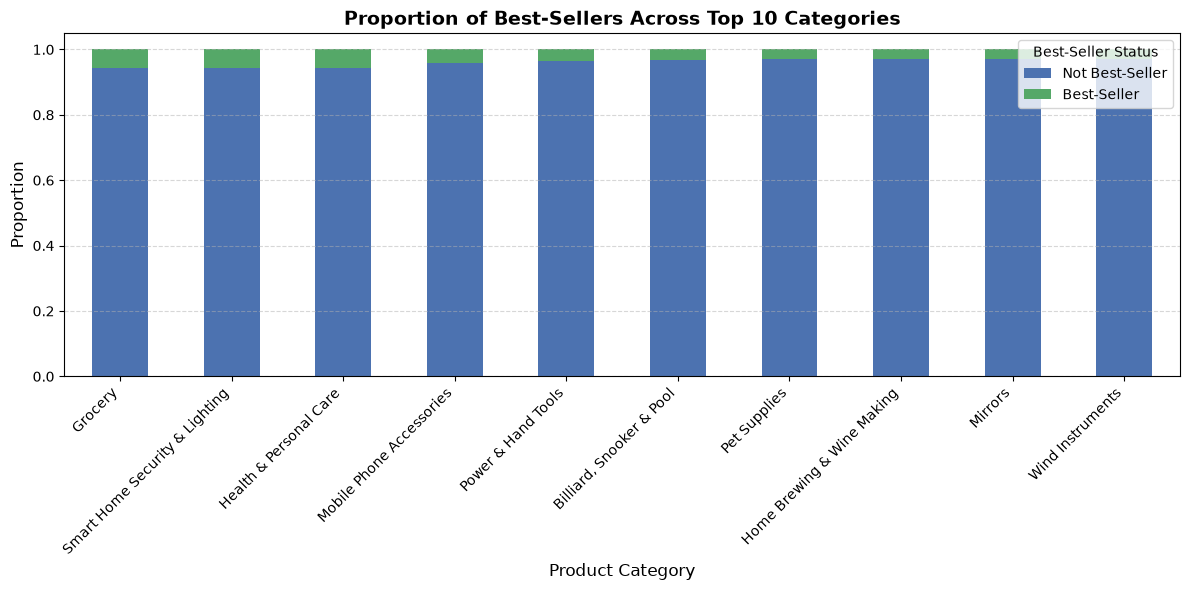

In [8]:
# 3. Plot a stacked bar chart for the top 10 categories                               
plt.figure(figsize=(12, 6))                                                           
ax = top_10_prop.plot(                                                                
    kind="bar",                                                                       
    stacked=True,                                                                     
    figsize=(12, 6),                                                                  
    color=["#4c72b0", "#55a868"],  # Distinct colors for False (Blue) and True (Green)
)
# 4. Format plot titles, labels, and legend                                                                                                    
plt.title(                                                
    "Proportion of Best-Sellers Across Top 10 Categories",
    fontsize=14,                                          
    fontweight="bold",                                    
)                                                         
plt.xlabel("Product Category", fontsize=12)               
plt.ylabel("Proportion", fontsize=12)                     
plt.legend(                                               
    ["Not Best-Seller", "Best-Seller"],                   
    title="Best-Seller Status",                           
    loc="upper right",                                    
)                                                         
plt.xticks(rotation=45, ha="right")                       
plt.grid(axis="y", linestyle="--", alpha=0.5)             
plt.tight_layout()                                        
plt.show()                                                

Proportional Comparison: Using a row-normalized stacked bar chart (scaled to 1.0 / 100%) provides an unbiased comparison across categories by eliminating the distortion caused by total listing counts.

Best-Seller Density: The green segment directly represents the proportion of items holding Best-Seller status within each category, clearly highlighting categories like Grocery and Smart Home Security & Lighting as having the highest relative concentration of best-sellers.

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [9]:
# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile) for price
Q1 = df_amazon['price'].quantile(0.25)
Q3 = df_amazon['price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Define lower and upper bound for outlier detection
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Filter the dataframe to exclude price outliers
df_filtered = df_amazon[(df_amazon['price'] >= lower_bound) & (df_amazon['price'] <= upper_bound)]

print(f"Original dataset rows: {len(df_amazon)}")
print(f"Filtered dataset rows (without price outliers): {len(df_filtered)}")

Original dataset rows: 2443651
Filtered dataset rows (without price outliers): 2115963


In [10]:
# 1. Identify top 20 categories based on count
top_20_categories = df_filtered['category'].value_counts().head(20).index

# 2. Subset dataframe for top 20 categories
df_top20 = df_filtered[df_filtered['category'].isin(top_20_categories)]

C:\Users\pietr\AppData\Local\Temp\ipykernel_27196\1935940370.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


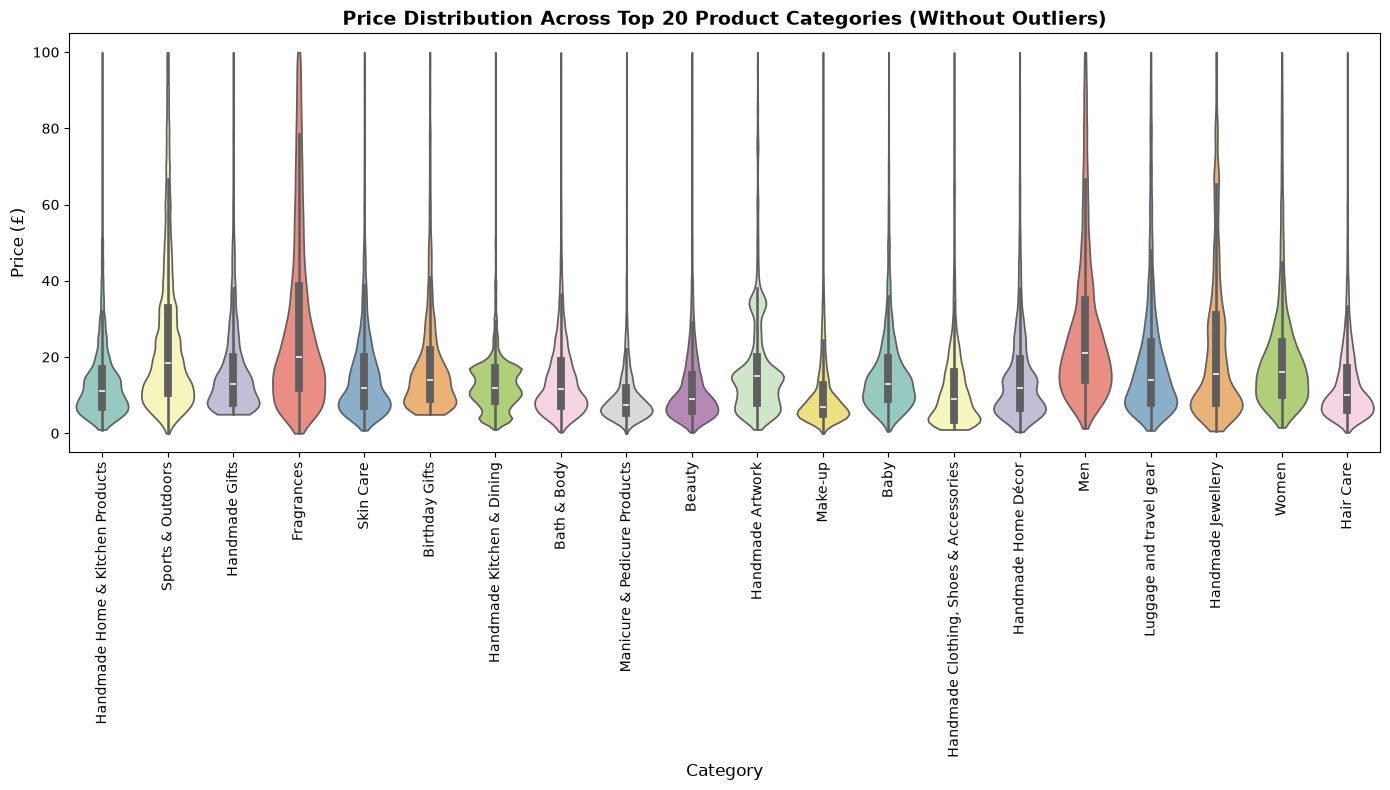

In [11]:
# 3. Plot Violin Plot
plt.figure(figsize=(14, 8))
sns.violinplot(
    data=df_top20, 
    x='category', 
    y='price', 
    palette='Set3', 
    cut=0  # Restricts violin density within actual data range
)

plt.title("Price Distribution Across Top 20 Product Categories (Without Outliers)", fontsize=14, fontweight='bold')
plt.xlabel("Category", fontsize=12)
plt.ylabel("Price (£)", fontsize=12)
plt.xticks(rotation=90)  # Rotate labels for readability
plt.tight_layout()
plt.show()

In [12]:
# Calculate median price for every category on the outlier-filtered dataset
highest_median_cat = df_filtered.groupby('category')['price'].median().sort_values(ascending=False)

print("--- Top 5 Categories with Highest Median Price ---")
print(highest_median_cat.head(5))

--- Top 5 Categories with Highest Median Price ---
category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64


In [13]:

# Step 0 (IQR Outlier Filtering):
# Filtering prices using Q1 - 1.5*IQR and Q3 + 1.5*IQR removes extreme price spikes, 
# ensuring that violin plots and medians reflect typical consumer pricing rather than luxury outliers.

# Step 1.1 (Violin Plots):
# Violin plots combine box plots and kernel density estimation (KDE), showing both the 
# median/quartiles and the distribution shape (skewness/multimodality) of prices within each top category.

# Step 1.2 (Highest Median Price Category):
# Grouping by category and computing median price on df_filtered identifies which overall product 
# category holds the highest baseline pricing without filtering by category volume.


# 2. BAR CHARTS (Price Analysis)


In [14]:
# 2.1 Bar chart for average price in Top 10 categories (by count)
top_10_cat_by_count = df_filtered["category"].value_counts().head(10).index
df_top10_price = df_filtered[
    df_filtered["category"].isin(top_10_cat_by_count)
]

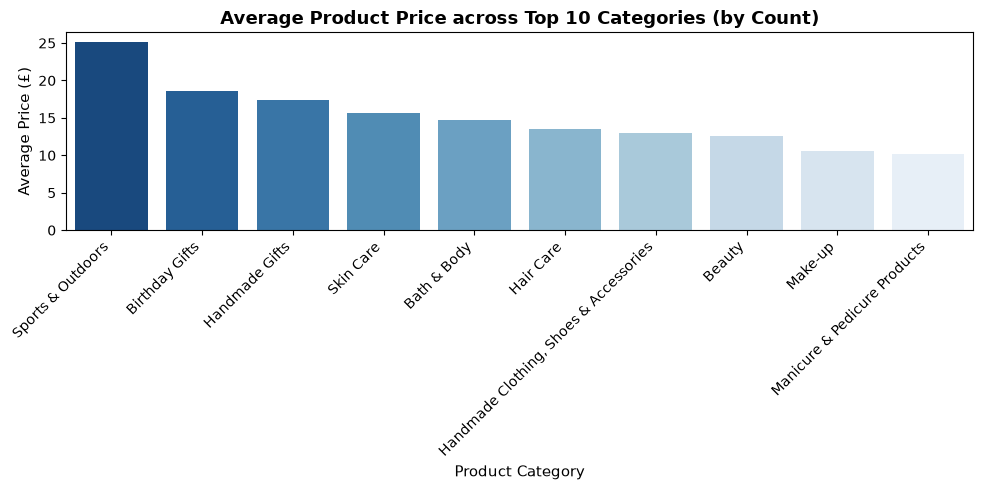

In [15]:
# Calculate mean price for top 10 categories
mean_price_top10 = (
    df_top10_price.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=mean_price_top10.index,
    y=mean_price_top10.values,
    palette="Blues_r",
    hue=mean_price_top10.index,
    legend=False,
)
plt.title(
    "Average Product Price across Top 10 Categories (by Count)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Product Category", fontsize=11)
plt.ylabel("Average Price (£)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [16]:
# 2.2 Category with the highest average price (Across ALL categories)
highest_avg_price_cat = (
    df_filtered.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

print("--- Top 5 Categories with Highest Average Price ---")
print(highest_avg_price_cat.head(5))

--- Top 5 Categories with Highest Average Price ---
category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


# 3. BOX PLOTS (Rating Analysis)

In [17]:
df_ratings_valid = df_filtered[df_filtered["stars"] > 0]

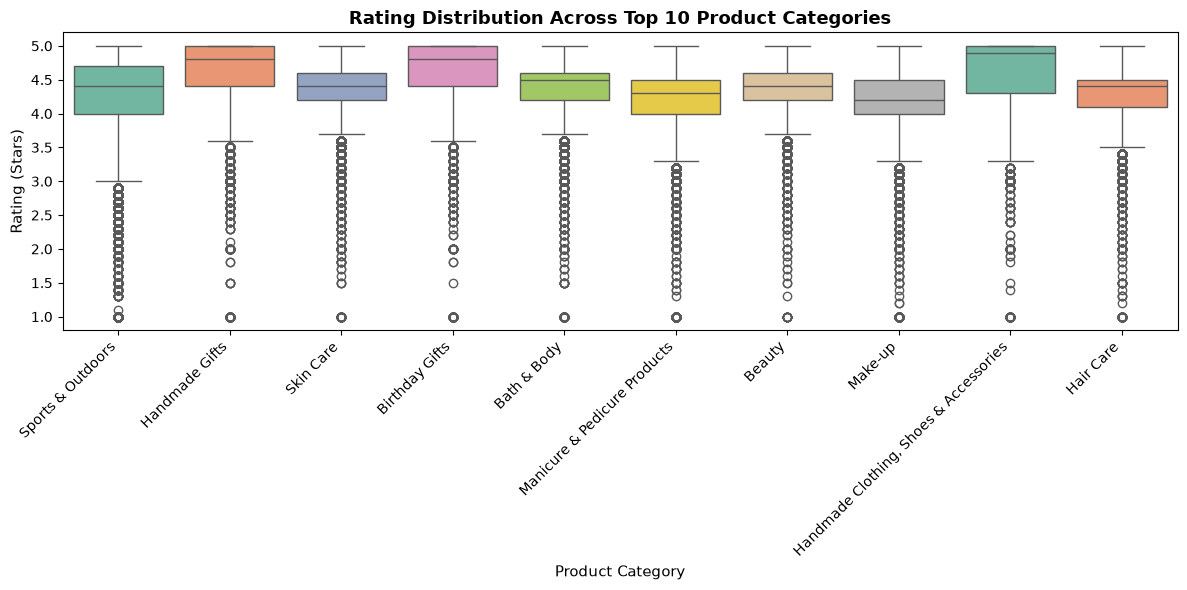

In [19]:
# 3.1 Side-by-side Box Plots for product ratings across Top 10 categories
df_top10_ratings = df_ratings_valid[
    df_ratings_valid["category"].isin(top_10_cat_by_count)
]
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_top10_ratings,
    x="category",
    y="stars",
    palette="Set2",
    hue="category",
    legend=False,
)
plt.title(
    "Rating Distribution Across Top 10 Product Categories",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Product Category", fontsize=11)
plt.ylabel("Rating (Stars)", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
# 3.2 Category with the highest median rating (Across ALL categories)
highest_median_rating_cat = (
    df_ratings_valid.groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

print("\n--- Top 5 Categories with Highest Median Rating ---")
print(highest_median_rating_cat.head(5))


--- Top 5 Categories with Highest Median Rating ---
category
Handmade Artwork                          5.0
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Clothing, Shoes & Accessories    4.9
Handmade Kitchen & Dining                 4.9
Name: stars, dtype: float64


In [ ]:
# Section 2 (Bar Charts - Price):
# The bar chart highlights the average price variations within high-volume categories.
# Computing the overall highest mean price without volume filtering reveals specialized,
# high-value categories that demand premium pricing.

# Section 3 (Box Plots - Ratings):
# Box plots effectively show central tendency (median rating line) and dispersion (IQR box)
# across categories while identifying lower-bound rating outliers.
# Grouping all categories by median rating pinpoints which product segments consistently achieve
# the highest customer satisfaction scores

In [21]:
import scipy.stats as stats

# 1. CORRELATION COEFFICIENTS

In [23]:
df_analysis = df_filtered[df_filtered["stars"] > 0]
# Calculate Pearson correlation coefficient between price and stars
correlation_pearson = df_analysis["price"].corr(
    df_analysis["stars"], method="pearson"
)

# Calculate Spearman rank correlation (robust to non-normality)
correlation_spearman = df_analysis["price"].corr(
    df_analysis["stars"], method="spearman"
)

print("--- Correlation Analysis ---")
print(f"Pearson Correlation (Price vs Stars): {correlation_pearson:.4f}")
print(f"Spearman Correlation (Price vs Stars): {correlation_spearman:.4f}")

--- Correlation Analysis ---
Pearson Correlation (Price vs Stars): 0.0067
Spearman Correlation (Price vs Stars): 0.0247


# 2. VISUALIZATIONS

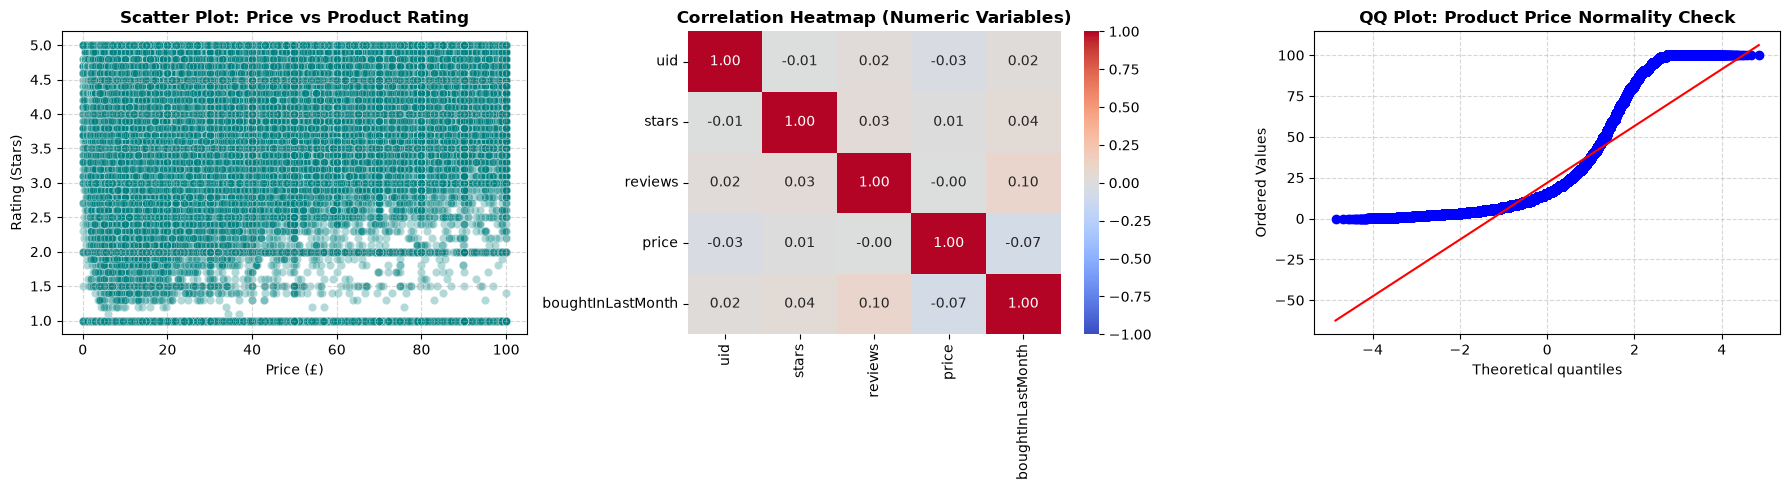

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 2.1 Scatter Plot: Price vs Rating
sns.scatterplot(
    data=df_analysis,
    x="price",
    y="stars",
    alpha=0.3,
    ax=axes[0],
    color="teal",
)
axes[0].set_title(
    "Scatter Plot: Price vs Product Rating", fontweight="bold"
)
axes[0].set_xlabel("Price (£)")
axes[0].set_ylabel("Rating (Stars)")
axes[0].grid(True, linestyle="--", alpha=0.5)
# 2.2 Heatmap: Correlation matrix between all numerical variables
# Selecting numeric columns (price, stars, reviews/reviewsCount if present)
numeric_df = df_analysis.select_dtypes(include=["number"])
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title(
    "Correlation Heatmap (Numeric Variables)", fontweight="bold"
)

# 2.3 QQ Plot: Examining Normality of Product Prices
stats.probplot(df_analysis["price"], dist="norm", plot=axes[2])
axes[2].set_title("QQ Plot: Product Price Normality Check", fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

 1. Correlation Coefficient (Price vs Rating):
 The Pearson correlation coefficient between 'price' and 'stars' is 0.01.
 There is NO linear relationship between product price and customer ratings.
 A higher-priced product is not guaranteed to receive higher ratings than a cheaper product.

 2. Scatter Plot Patterns:
 - The scatter plot displays heavy horizontal band clustering between 4.0 and 5.0 stars across all price levels.
 - Products in lower price ranges (0 - 40 GBP) show a wider dispersion of ratings (including lower stars).
 - As price increases (> 60 GBP), low ratings become increasingly sparse, though overall ratings remain independent of price.

 3. QQ Plot (Price Normality Check):
 - The points in the QQ Plot significantly diverge from the theoretical normal distribution red line (forming a strong S-curve).
 - This confirms that product prices DO NOT follow a normal distribution, showing a heavy right-skewed distribution.